# Lab 09: Mạng Nơ-ron Nhân tạo (MLP - Multi-Layer Perceptron)



## Phần 1: Cài đặt thư viện và chuẩn bị môi trường


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error, r2_score
from sklearn.datasets import load_digits
from sklearn.pipeline import make_pipeline

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)
print("Thư viện đã sẵn sàng.")


Thư viện đã sẵn sàng.


## Phần 2: Perceptron và Vấn đề XOR
- Tính toán thuận của một nơ-ron đơn lẻ: $z = w_1 x_1 + w_2 x_2 + b$, $a = \sigma(z) = \frac{1}{1 + e^{-z}}$.
- Một nơ-ron đơn lẻ chỉ tạo ra siêu phẳng tuyến tính, không thể giải được bài toán phi tuyến XOR.


In [2]:
# 1. Tính toán nơ-ron đơn lẻ
w = np.array([0.5, -0.3])
b = 0.1
x = np.array([2.0, -1.0])

z = np.dot(w, x) + b
a = 1 / (1 + np.exp(-z))
print(f"Đầu vào x: {x}")
print(f"Tổng có trọng số z: {z:.4f}")
print(f"Đầu ra sau hàm Sigmoid a: {a:.4f}")


Đầu vào x: [ 2. -1.]
Tổng có trọng số z: 1.4000
Đầu ra sau hàm Sigmoid a: 0.8022


In [3]:
# 2. Mô phỏng mạng 2 lớp giải quyết XOR bằng tay (2 nơ-ron ẩn ReLU + 1 nơ-ron ra)
# Bảng chân trị XOR: [0,0]->0, [0,1]->1, [1,0]->1, [1,1]->0
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

# Nơ-ron ẩn: h1 = max(0, x1 - x2), h2 = max(0, x2 - x1)
# Nơ-ron ra: y = h1 + h2
def xor_manual(X):
    h1 = np.maximum(0, X[:, 0] - X[:, 1])
    h2 = np.maximum(0, X[:, 1] - X[:, 0])
    return h1 + h2

y_manual = xor_manual(X_xor)
print("Kết quả tính toán tay cho XOR:")
for xi, yi in zip(X_xor, y_manual):
    print(f"Input: {xi} -> Output: {yi}")


Kết quả tính toán tay cho XOR:
Input: [0 0] -> Output: 0
Input: [0 1] -> Output: 1
Input: [1 0] -> Output: 1
Input: [1 1] -> Output: 0


## Phần 3: MLPClassifier và Kiến trúc mạng trên dữ liệu XOR
- Thử nghiệm mô hình tuyến tính (Logistic Regression) vs MLPClassifier với các số lượng nơ-ron ẩn khác nhau.


In [4]:
# Đọc dữ liệu XOR
df_xor = pd.read_csv('data/xor.csv')
X_xor_data = df_xor[['x1', 'x2']].values
y_xor_data = df_xor['nhan'].values

X_tr_xor, X_te_xor, y_tr_xor, y_te_xor = train_test_split(X_xor_data, y_xor_data, test_size=0.3, random_state=42)

# 1. Logistic Regression
lr = LogisticRegression()
lr.fit(X_tr_xor, y_tr_xor)
acc_lr = lr.score(X_te_xor, y_te_xor)
print(f"Độ chính xác Logistic Regression trên XOR: {acc_lr:.4f} (Không thể phân tách phi tuyến)")


Độ chính xác Logistic Regression trên XOR: 0.5167 (Không thể phân tách phi tuyến)


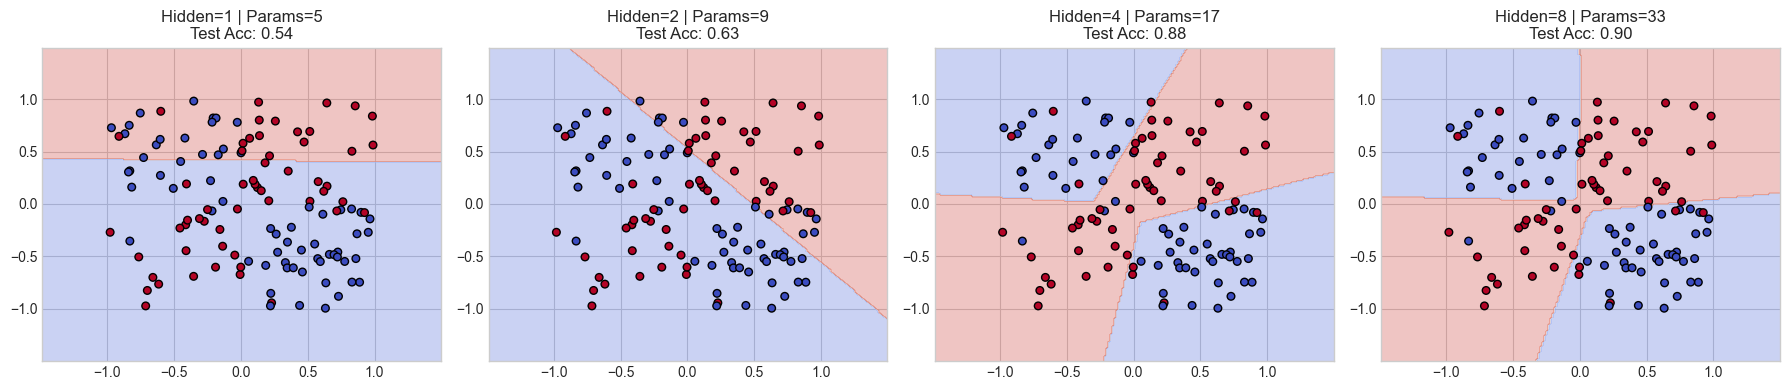

In [5]:
# 2. MLPClassifier với các kích thước tầng ẩn: [1, 2, 4, 8]
hidden_sizes = [1, 2, 4, 8]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

x_min, x_max = X_xor_data[:, 0].min() - 0.5, X_xor_data[:, 0].max() + 0.5
y_min, y_max = X_xor_data[:, 1].min() - 0.5, X_xor_data[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

for idx, h in enumerate(hidden_sizes):
    mlp = MLPClassifier(hidden_layer_sizes=(h,), activation='relu', max_iter=2000, random_state=42)
    mlp.fit(X_tr_xor, y_tr_xor)
    acc = mlp.score(X_te_xor, y_te_xor)
    n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
    
    Z = mlp.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    axes[idx].scatter(X_te_xor[:, 0], X_te_xor[:, 1], c=y_te_xor, cmap='coolwarm', edgecolors='k', s=30)
    axes[idx].set_title(f"Hidden={h} | Params={n_params}\nTest Acc: {acc:.2f}")

plt.tight_layout()
plt.show()


## Phần 4: Regularization và Tinh chỉnh siêu tham số (Dữ liệu Hai Vầng Trăng)
- Ảnh hưởng của tham số phạt L2 (`alpha`) và số lượng nơ-ron đối với nguy cơ Overfitting / Underfitting.


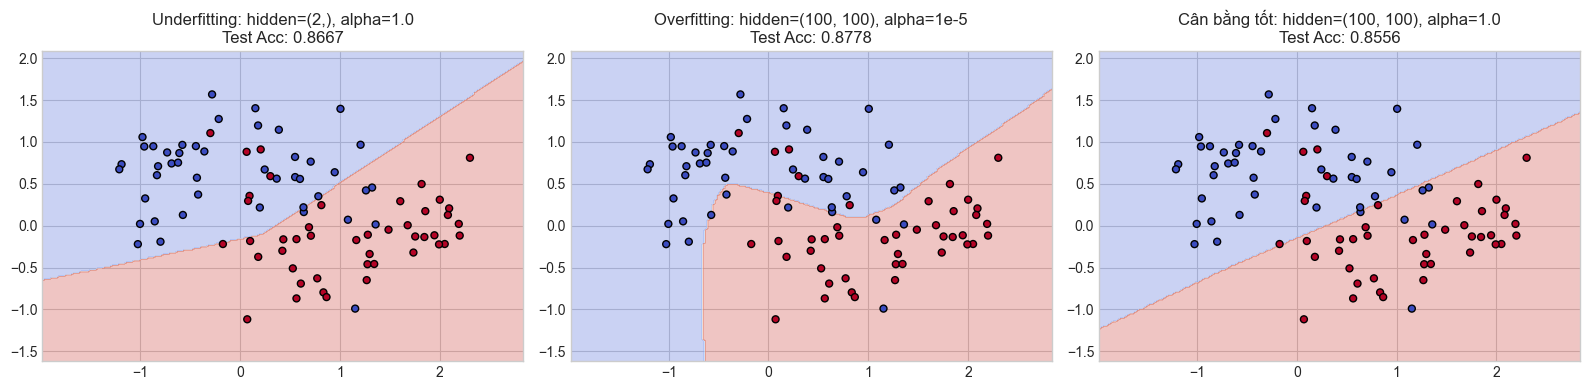

In [6]:
df_moons = pd.read_csv('data/hai_vang_trang.csv')
X_moons = df_moons[['x1', 'x2']].values
y_moons = df_moons['nhan'].values

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)

configs = [
    ("Underfitting: hidden=(2,), alpha=1.0", (2,), 1.0),
    ("Overfitting: hidden=(100, 100), alpha=1e-5", (100, 100), 1e-5),
    ("Cân bằng tốt: hidden=(100, 100), alpha=1.0", (100, 100), 1.0)
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
xx_m, yy_m = np.meshgrid(np.linspace(X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5, 200),
                         np.linspace(X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5, 200))

for idx, (title, hidden, alpha) in enumerate(configs):
    mlp = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, max_iter=2000, random_state=42)
    mlp.fit(X_tr_m, y_tr_m)
    acc = mlp.score(X_te_m, y_te_m)
    
    Z = mlp.predict(np.c_[xx_m.ravel(), yy_m.ravel()]).reshape(xx_m.shape)
    axes[idx].contourf(xx_m, yy_m, Z, alpha=0.3, cmap='coolwarm')
    axes[idx].scatter(X_te_m[:, 0], X_te_m[:, 1], c=y_te_m, cmap='coolwarm', edgecolors='k', s=25)
    axes[idx].set_title(f"{title}\nTest Acc: {acc:.4f}")

plt.tight_layout()
plt.show()


## Phần 5: Tiền xử lý dữ liệu cho MLP (Tầm quan trọng của Chuẩn hóa)
- MLP tối ưu bằng Gradient Descent nên cực kỳ nhạy cảm với thang đo của đặc trưng.


In [7]:
df_sv = pd.read_csv('data/sinh_vien_mo_rong.csv')
X_sv = df_sv.drop(columns=['qua_mon']).values
y_sv = df_sv['qua_mon'].values

X_tr_sv, X_te_sv, y_tr_sv, y_te_sv = train_test_split(X_sv, y_sv, test_size=0.3, random_state=42)

# 1. Không chuẩn hóa
mlp_raw = MLPClassifier(hidden_layer_sizes=(50,), max_iter=500, random_state=42)
mlp_raw.fit(X_tr_sv, y_tr_sv)
acc_raw = mlp_raw.score(X_te_sv, y_te_sv)

# 2. Có chuẩn hóa qua StandardScaler
scaler = StandardScaler()
X_tr_sv_s = scaler.fit_transform(X_tr_sv)
X_te_sv_s = scaler.transform(X_te_sv)

mlp_scaled = MLPClassifier(hidden_layer_sizes=(50,), max_iter=500, random_state=42)
mlp_scaled.fit(X_tr_sv_s, y_tr_sv)
acc_scaled = mlp_scaled.score(X_te_sv_s, y_te_sv)

print(f"Độ chính xác khi KHÔNG chuẩn hóa: {acc_raw:.4f} (Chỉ dự đoán 1 lớp, gradient bị nghẽn)")
print(f"Độ chính xác khi CÓ chuẩn hóa:    {acc_scaled:.4f}")


Độ chính xác khi KHÔNG chuẩn hóa: 0.6944 (Chỉ dự đoán 1 lớp, gradient bị nghẽn)
Độ chính xác khi CÓ chuẩn hóa:    0.8611


## Phần 6: Phân loại chữ số viết tay (Digits Dataset) & Early Stopping


In [8]:
digits = load_digits()
X_d, y_d = digits.data, digits.target
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_d, y_d, test_size=0.25, random_state=42, stratify=y_d)

scaler_d = StandardScaler()
X_tr_d_s = scaler_d.fit_transform(X_tr_d)
X_te_d_s = scaler_d.transform(X_te_d)

# 1. Huấn luyện MLP tiêu chuẩn
mlp_digits = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42)
mlp_digits.fit(X_tr_d_s, y_tr_d)
pred_d = mlp_digits.predict(X_te_d_s)

n_params = sum(w.size for w in mlp_digits.coefs_) + sum(b.size for b in mlp_digits.intercepts_)
print(f"Kiến trúc: 64 -> 100 -> 10")
print(f"Tổng số tham số: {n_params} (Weights: 64*100 + 100*10 = 7400, Biases: 100 + 10 = 110)")
print(f"Số epoch hội tụ: {mlp_digits.n_iter_}")
print(f"Độ chính xác Test: {accuracy_score(y_te_d, pred_d):.4f}")

# 2. Huấn luyện với Early Stopping
mlp_early = MLPClassifier(hidden_layer_sizes=(100,), early_stopping=True, n_iter_no_change=10, max_iter=300, random_state=42)
mlp_early.fit(X_tr_d_s, y_tr_d)
print(f"Early Stopping dừng tại epoch: {mlp_early.n_iter_} (Độ chính xác: {mlp_early.score(X_te_d_s, y_te_d):.4f})")


Kiến trúc: 64 -> 100 -> 10
Tổng số tham số: 7510 (Weights: 64*100 + 100*10 = 7400, Biases: 100 + 10 = 110)
Số epoch hội tụ: 147
Độ chính xác Test: 0.9800
Early Stopping dừng tại epoch: 39 (Độ chính xác: 0.9600)


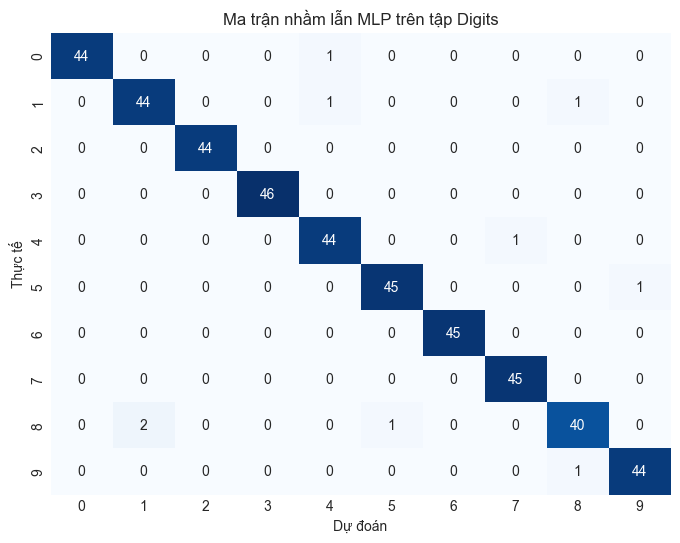

In [9]:
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_te_d, pred_d)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Ma trận nhầm lẫn MLP trên tập Digits")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()


## Bài tập 1: Tính toán thuận thủ công (Forward Pass)
- So sánh kết quả tính bằng công thức ma trận thủ công với kết quả của hàm `predict_proba` từ Scikit-learn.


In [10]:
mlp_xor = MLPClassifier(hidden_layer_sizes=(2,), activation='relu', max_iter=2000, random_state=42)
mlp_xor.fit(X_xor_data, y_xor_data)

# Trích xuất trọng số và bias
W1, W2 = mlp_xor.coefs_
b1, b2 = mlp_xor.intercepts_

def forward_pass_manual(X):
    # Tầng ẩn: ReLU
    z1 = np.dot(X, W1) + b1
    h = np.maximum(0, z1)
    # Tầng ra: Sigmoid (đối với bài toán phân loại nhị phân)
    z2 = np.dot(h, W2) + b2
    prob = 1 / (1 + np.exp(-z2))
    return prob.ravel()

prob_manual = forward_pass_manual(X_xor_data[:5])
prob_sklearn = mlp_xor.predict_proba(X_xor_data[:5])[:, 1]

df_cmp = pd.DataFrame({
    'X1': X_xor_data[:5, 0],
    'X2': X_xor_data[:5, 1],
    'Prob_Manual': prob_manual,
    'Prob_Sklearn': prob_sklearn,
    'Diff': np.abs(prob_manual - prob_sklearn)
})
print("So sánh Forward Pass thủ công và predict_proba:")
print(df_cmp.to_string(index=False))
print(f"\nSai số lớn nhất: {df_cmp['Diff'].max():.8e}")


So sánh Forward Pass thủ công và predict_proba:
     X1      X2  Prob_Manual  Prob_Sklearn  Diff
 0.2739 -0.4604     0.435538      0.435538   0.0
-0.9181 -0.9669     0.435538      0.435538   0.0
 0.6265  0.8255     0.851562      0.851562   0.0
 0.2133  0.4590     0.574283      0.574283   0.0
 0.0872  0.8701     0.688545      0.688545   0.0

Sai số lớn nhất: 0.00000000e+00


## Bài tập 2: Thiết kế mạng nơ-ron thủ công cho hàm XOR bằng ReLU
- Kiến trúc mạng nơ-ron:
  - Tầng vào: $x = (x_1, x_2) \in \{0, 1\}^2$
  - Tầng ẩn: 2 nơ-ron kích hoạt ReLU:
    $$h_1 = \text{ReLU}(x_1 - x_2) = \max(0, x_1 - x_2)$$
    $$h_2 = \text{ReLU}(x_2 - x_1) = \max(0, x_2 - x_1)$$
  - Tầng ra: Nơ-ron tuyến tính kết hợp 2 nơ-ron ẩn:
    $$y = 1 \cdot h_1 + 1 \cdot h_2 + 0$$


In [11]:
inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

h1 = np.maximum(0, inputs[:, 0] - inputs[:, 1])
h2 = np.maximum(0, inputs[:, 1] - inputs[:, 0])
y_out = h1 + h2

df_bt2 = pd.DataFrame({
    'x1': inputs[:, 0],
    'x2': inputs[:, 1],
    'h1 = max(0, x1-x2)': h1,
    'h2 = max(0, x2-x1)': h2,
    'y = h1 + h2': y_out,
    'XOR Ground Truth': [0, 1, 1, 0]
})
print(df_bt2.to_string(index=False))


 x1  x2  h1 = max(0, x1-x2)  h2 = max(0, x2-x1)  y = h1 + h2  XOR Ground Truth
  0   0                   0                   0            0                 0
  0   1                   0                   1            1                 1
  1   0                   1                   0            1                 1
  1   1                   0                   0            0                 0


## Bài tập 3: So sánh hàm kích hoạt trên dữ liệu Hai Vầng Trăng
- So sánh 3 hàm kích hoạt: `logistic` (Sigmoid), `tanh` và `relu` với cùng kiến trúc `(20, 20)`.


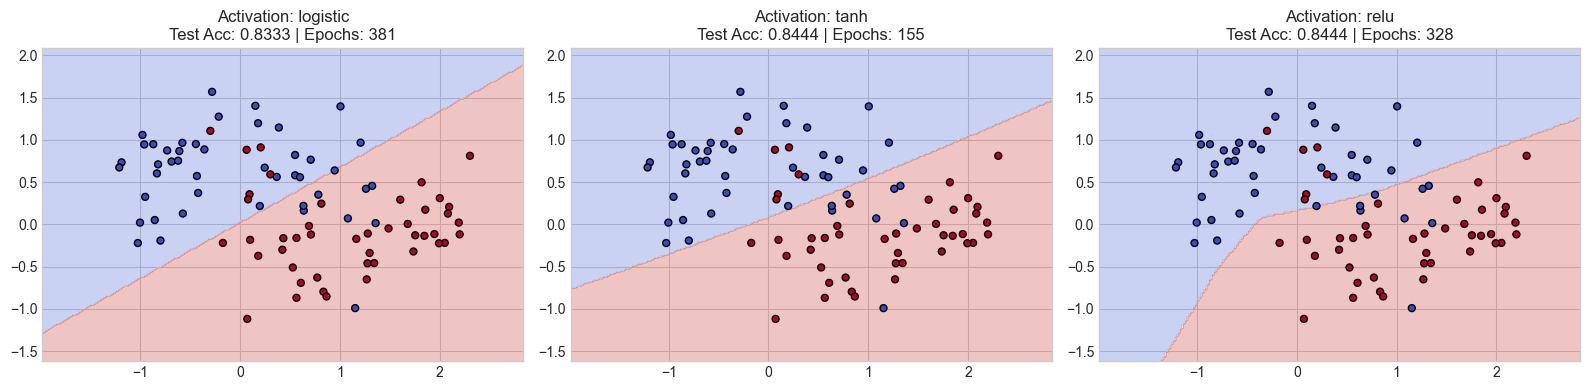

In [12]:
activations = ['logistic', 'tanh', 'relu']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for idx, act in enumerate(activations):
    mlp_act = MLPClassifier(hidden_layer_sizes=(20, 20), activation=act, max_iter=2000, random_state=42)
    mlp_act.fit(X_tr_m, y_tr_m)
    acc = mlp_act.score(X_te_m, y_te_m)
    
    Z = mlp_act.predict(np.c_[xx_m.ravel(), yy_m.ravel()]).reshape(xx_m.shape)
    axes[idx].contourf(xx_m, yy_m, Z, alpha=0.3, cmap='coolwarm')
    axes[idx].scatter(X_te_m[:, 0], X_te_m[:, 1], c=y_te_m, cmap='coolwarm', edgecolors='k', s=25)
    axes[idx].set_title(f"Activation: {act}\nTest Acc: {acc:.4f} | Epochs: {mlp_act.n_iter_}")

plt.tight_layout()
plt.show()


## Bài tập 4: Thử nghiệm tốc độ học (Learning Rate Init)
- Khảo sát các giá trị `learning_rate_init`: $[0.0001, 0.001, 0.01, 0.1]$ trên dữ liệu hai vầng trăng.
- Vẽ biểu đồ đường cong mất mát (Loss curve) và lưu ảnh `toc_do_hoc.png`.


Đã lưu đồ thị vào toc_do_hoc.png


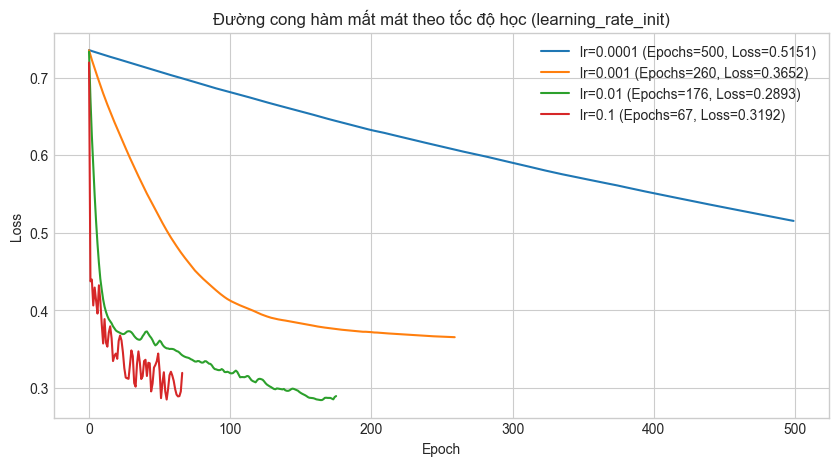

In [13]:
lr_rates = [0.0001, 0.001, 0.01, 0.1]
plt.figure(figsize=(10, 5))

for lr_val in lr_rates:
    mlp_lr = MLPClassifier(hidden_layer_sizes=(50,), learning_rate_init=lr_val, solver='adam', max_iter=500, random_state=42)
    mlp_lr.fit(X_tr_m, y_tr_m)
    plt.plot(mlp_lr.loss_curve_, label=f"lr={lr_val} (Epochs={mlp_lr.n_iter_}, Loss={mlp_lr.loss_:.4f})")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Đường cong hàm mất mát theo tốc độ học (learning_rate_init)")
plt.legend()
plt.savefig('toc_do_hoc.png', dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu đồ thị vào toc_do_hoc.png")


## Bài tập 5: Tinh chỉnh siêu tham số trên Digits Dataset bằng GridSearchCV
- Tìm kiếm lưới kết hợp giữa `hidden_layer_sizes` và `alpha`.


In [14]:
param_grid = {
    'mlpclassifier__hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'mlpclassifier__alpha': [0.0001, 0.01, 1.0]
}

pipe = make_pipeline(
    StandardScaler(),
    MLPClassifier(max_iter=300, random_state=42)
)

grid = GridSearchCV(pipe, param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_tr_d, y_tr_d)

print(f"Tham số tốt nhất: {grid.best_params_}")
print(f"Độ chính xác CV tốt nhất: {grid.best_score_:.4f}")

best_model = grid.best_estimator_
acc_test = best_model.score(X_te_d, y_te_d)
print(f"Độ chính xác trên tập kiểm tra (Test Set): {acc_test:.4f}")


Tham số tốt nhất: {'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (100,)}
Độ chính xác CV tốt nhất: 0.9755
Độ chính xác trên tập kiểm tra (Test Set): 0.9800


## Bài tập 6: Mạng nơ-ron Hồi quy (MLPRegressor) & Khả năng Ngoại suy
- Dự đoán giá nhà dựa trên diện tích từ `data/gia_nha.csv`.
- So sánh khả năng ngoại suy ngoài miền huấn luyện giữa MLPRegressor và Cây quyết định (Decision Tree / Random Forest).


MLPRegressor Fit - RMSE: 0.4363 tỷ, R2: 0.9281
Dự đoán giá nhà cho căn 250m2: 27.56 tỷ đồng.
Nhận xét về ngoại suy:
- MLP với hàm kích hoạt ReLU tạo thành các đoạn thẳng tuyến tính từng khúc (piecewise linear).
  Khi ra ngoài phạm vi huấn luyện (x > 150m2), nó tiếp tục ngoại suy tuyến tính theo độ dốc của đoạn cuối cùng.
- Ngược lại, Cây quyết định / Rừng ngẫu nhiên chỉ dự đoán giá trị trung bình của lá cuối cùng (đường nằm ngang, không thể ngoại suy tăng tiếp).


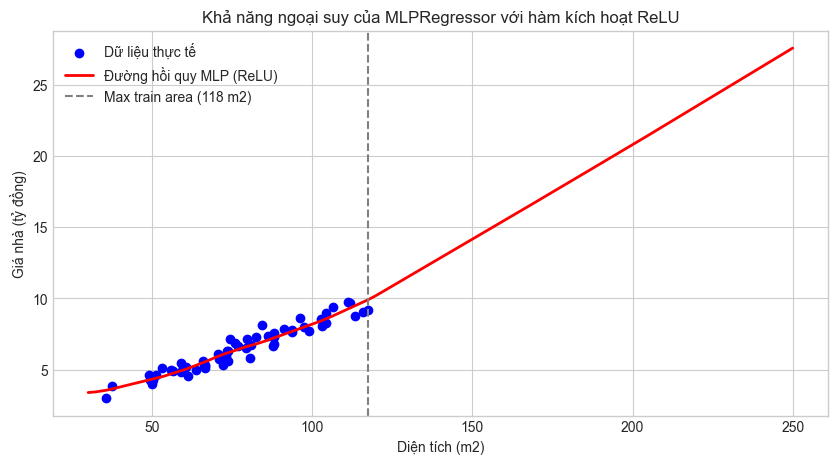

In [15]:
df_nha = pd.read_csv('data/gia_nha.csv')
X_nha = df_nha[['dien_tich']].values
y_nha = df_nha['gia'].values

scaler_X = StandardScaler()
X_nha_s = scaler_X.fit_transform(X_nha)

# Huấn luyện MLPRegressor
mlp_reg = MLPRegressor(hidden_layer_sizes=(50, 50), activation='relu', max_iter=2000, random_state=42)
mlp_reg.fit(X_nha_s, y_nha)

y_pred_nha = mlp_reg.predict(X_nha_s)
rmse = np.sqrt(mean_squared_error(y_nha, y_pred_nha))
r2 = r2_score(y_nha, y_pred_nha)
print(f"MLPRegressor Fit - RMSE: {rmse:.4f} tỷ, R2: {r2:.4f}")

# Khảo sát ngoại suy với diện tích từ 30 đến 250 m2 (Dữ liệu gốc chỉ từ ~40 đến 150 m2)
X_test_ext = np.linspace(30, 250, 200).reshape(-1, 1)
y_pred_ext = mlp_reg.predict(scaler_X.transform(X_test_ext))

plt.figure(figsize=(10, 5))
plt.scatter(X_nha, y_nha, color='blue', label='Dữ liệu thực tế')
plt.plot(X_test_ext, y_pred_ext, color='red', linewidth=2, label='Đường hồi quy MLP (ReLU)')
plt.axvline(x=X_nha.max(), color='gray', linestyle='--', label=f'Max train area ({X_nha.max():.0f} m2)')
plt.xlabel('Diện tích (m2)')
plt.ylabel('Giá nhà (tỷ đồng)')
plt.title('Khả năng ngoại suy của MLPRegressor với hàm kích hoạt ReLU')
plt.legend()
plt.show()

# Dự đoán căn 250 m2
can_250 = scaler_X.transform([[250]])
gia_250 = mlp_reg.predict(can_250)[0]
print(f"Dự đoán giá nhà cho căn 250m2: {gia_250:.2f} tỷ đồng.")
print("Nhận xét về ngoại suy:")
print("- MLP với hàm kích hoạt ReLU tạo thành các đoạn thẳng tuyến tính từng khúc (piecewise linear).")
print("  Khi ra ngoài phạm vi huấn luyện (x > 150m2), nó tiếp tục ngoại suy tuyến tính theo độ dốc của đoạn cuối cùng.")
print("- Ngược lại, Cây quyết định / Rừng ngẫu nhiên chỉ dự đoán giá trị trung bình của lá cuối cùng (đường nằm ngang, không thể ngoại suy tăng tiếp).")
